In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    precision_recall_curve
)

import joblib
import os

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
expiry_df = pd.read_csv(
    "../data/processed/expiry_risk_dataset.csv",
    parse_dates=["snapshot_date"]
)

print("Dataset shape:", expiry_df.shape)

print(expiry_df.head())

print("\nClass distribution:")
print(expiry_df["expiry_risk"].value_counts())

Dataset shape: (2500, 10)
  snapshot_date product_id          batch_id  current_stock  days_to_expiry  \
0    2025-07-01     MED001  MED001_202507_B1            797              59   
1    2025-07-01     MED001  MED001_202507_B2            495             249   
2    2025-07-01     MED001  MED001_202507_B3            873             175   
3    2025-07-01     MED001  MED001_202507_B4            728              58   
4    2025-07-01     MED001  MED001_202507_B5            184              97   

   avg_daily_demand_30d  avg_daily_demand_90d  expected_demand  \
0             42.733333             35.022222      2066.311111   
1             42.733333             35.022222      8720.533333   
2             42.733333             35.022222      6128.888889   
3             42.733333             35.022222      2031.288889   
4             42.733333             35.022222      3397.155556   

   stock_demand_ratio  expiry_risk  
0            0.385712            0  
1            0.056763       

In [3]:
feature_columns = [
    "product_id",
    "current_stock",
    "days_to_expiry",
    "avg_daily_demand_30d",
    "avg_daily_demand_90d",
    "expected_demand",
    "stock_demand_ratio"
]

target_column = "expiry_risk"

X = expiry_df[feature_columns]
y = expiry_df[target_column]

print("Features:", X.shape)
print("Target:", y.shape)

Features: (2500, 7)
Target: (2500,)


In [4]:
train_df = expiry_df[
    expiry_df["snapshot_date"] < "2025-10-01"
].copy()

val_df = expiry_df[
    (expiry_df["snapshot_date"] >= "2025-10-01") &
    (expiry_df["snapshot_date"] < "2025-11-01")
].copy()

test_df = expiry_df[
    expiry_df["snapshot_date"] >= "2025-11-01"
].copy()

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

print("\nTraining class distribution:")
print(train_df["expiry_risk"].value_counts())

print("\nValidation class distribution:")
print(val_df["expiry_risk"].value_counts())

print("\nTest class distribution:")
print(test_df["expiry_risk"].value_counts())

Train: (1500, 10)
Validation: (500, 10)
Test: (500, 10)

Training class distribution:
expiry_risk
0    1402
1      98
Name: count, dtype: int64

Validation class distribution:
expiry_risk
0    471
1     29
Name: count, dtype: int64

Test class distribution:
expiry_risk
0    462
1     38
Name: count, dtype: int64


In [5]:
X_train = train_df[feature_columns]
y_train = train_df[target_column]

X_val = val_df[feature_columns]
y_val = val_df[target_column]

X_test = test_df[feature_columns]
y_test = test_df[target_column]

# One-hot encode product ID
X_train = pd.get_dummies(X_train)

X_val = pd.get_dummies(X_val).reindex(
    columns=X_train.columns,
    fill_value=0
)

X_test = pd.get_dummies(X_test).reindex(
    columns=X_train.columns,
    fill_value=0
)

print("Training features:", X_train.shape)

Training features: (1500, 106)


In [6]:
baseline_val_predictions = (
    (
        val_df["current_stock"] -
        val_df["expected_demand"]
    ) / val_df["current_stock"]
    >= 0.10
).astype(int)

print(
    classification_report(
        y_val,
        baseline_val_predictions,
        zero_division=0
    )
)

              precision    recall  f1-score   support

           0       0.96      1.00      0.98       471
           1       1.00      0.31      0.47        29

    accuracy                           0.96       500
   macro avg       0.98      0.66      0.73       500
weighted avg       0.96      0.96      0.95       500



In [7]:
rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=12,
    min_samples_split=5,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Expiry Risk Random Forest trained!")

Expiry Risk Random Forest trained!


In [8]:
val_probabilities = rf_model.predict_proba(X_val)[:, 1]

val_predictions = (
    val_probabilities >= 0.5
).astype(int)

print(
    classification_report(
        y_val,
        val_predictions,
        target_names=["Low Risk", "High Risk"],
        zero_division=0
    )
)

              precision    recall  f1-score   support

    Low Risk       1.00      0.90      0.95       471
   High Risk       0.37      0.97      0.54        29

    accuracy                           0.90       500
   macro avg       0.69      0.93      0.74       500
weighted avg       0.96      0.90      0.92       500



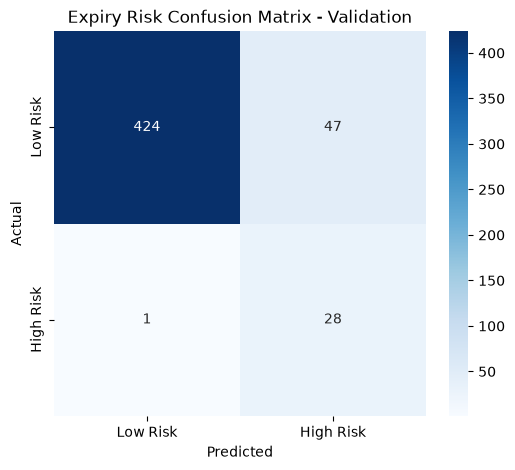

In [9]:
cm = confusion_matrix(
    y_val,
    val_predictions
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Low Risk", "High Risk"],
    yticklabels=["Low Risk", "High Risk"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Expiry Risk Confusion Matrix - Validation")

plt.show()

In [10]:
thresholds = np.arange(0.10, 0.91, 0.05)

threshold_results = []

for threshold in thresholds:

    predictions = (
        val_probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        "threshold": threshold,
        "precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "f1": f1_score(
            y_val, predictions, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df)

best_threshold = threshold_df.loc[
    threshold_df["f1"].idxmax(),
    "threshold"
]

print("Selected threshold:", best_threshold)

,threshold,precision,recall,f1
0,0.10,0.193333,1.000000,0.324022
1,0.15,0.223077,1.000000,0.364780
2,0.20,0.250000,1.000000,0.400000
3,0.25,0.261261,1.000000,0.414286
4,0.30,0.276190,1.000000,0.432836
5,0.35,0.315217,1.000000,0.479339
6,0.40,0.325581,0.965517,0.486957
7,0.45,0.341463,0.965517,0.504505
8,0.50,0.373333,0.965517,0.538462
9,0.55,0.415385,0.931034,0.574468


Selected threshold: 0.8000000000000002


In [11]:
train_val_df = pd.concat(
    [train_df, val_df],
    ignore_index=True
)

X_train_val = pd.get_dummies(
    train_val_df[feature_columns]
)

X_test_final = pd.get_dummies(
    test_df[feature_columns]
).reindex(
    columns=X_train_val.columns,
    fill_value=0
)

y_train_val = train_val_df[target_column]

final_rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=12,
    min_samples_split=5,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

final_rf_model.fit(X_train_val, y_train_val)

test_probabilities = final_rf_model.predict_proba(
    X_test_final
)[:, 1]

test_predictions = (
    test_probabilities >= best_threshold
).astype(int)

print(
    classification_report(
        y_test,
        test_predictions,
        target_names=["Low Risk", "High Risk"],
        zero_division=0
    )
)

              precision    recall  f1-score   support

    Low Risk       0.96      0.97      0.97       462
   High Risk       0.59      0.50      0.54        38

    accuracy                           0.94       500
   macro avg       0.78      0.74      0.75       500
weighted avg       0.93      0.94      0.93       500



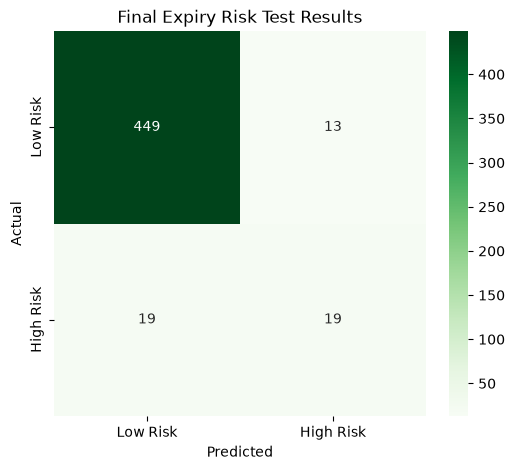

In [12]:
cm = confusion_matrix(
    y_test,
    test_predictions
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Low Risk", "High Risk"],
    yticklabels=["Low Risk", "High Risk"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Final Expiry Risk Test Results")

plt.show()

In [13]:
baseline_test_predictions = (
    (
        test_df["current_stock"] -
        test_df["expected_demand"]
    ) / test_df["current_stock"]
    >= 0.10
).astype(int)

results = pd.DataFrame({
    "Model": ["Rule-Based Baseline", "Random Forest"],
    "Precision": [
        precision_score(
            y_test, baseline_test_predictions,
            zero_division=0
        ),
        precision_score(
            y_test, test_predictions,
            zero_division=0
        )
    ],
    "Recall": [
        recall_score(
            y_test, baseline_test_predictions,
            zero_division=0
        ),
        recall_score(
            y_test, test_predictions,
            zero_division=0
        )
    ],
    "F1": [
        f1_score(
            y_test, baseline_test_predictions,
            zero_division=0
        ),
        f1_score(
            y_test, test_predictions,
            zero_division=0
        )
    ]
})

display(results)

,Model,Precision,Recall,F1
0,Rule-Based Baseline,0.923077,0.315789,0.470588
1,Random Forest,0.593750,0.500000,0.542857


In [14]:
os.makedirs("../models", exist_ok=True)
os.makedirs("../reports", exist_ok=True)

expiry_artifact = {
    "model": final_rf_model,
    "feature_columns": list(X_train_val.columns),
    "threshold": float(best_threshold),
    "model_name": "Random Forest Classifier"
}

joblib.dump(
    expiry_artifact,
    "../models/expiry_risk_model.pkl"
)

results.to_csv(
    "../reports/expiry_model_metrics.csv",
    index=False
)

print("Expiry model saved successfully!")

Expiry model saved successfully!
